# Lesson 5: Baseline Model (Logistic Regression)

**Goals of this notebook:**
1. Train a first model, **Logistic Regression**, as a simple and interpretable **baseline**.
2. Learn how to **evaluate** a model properly on **imbalanced** data (about 26.5% churn), and see why accuracy alone is misleading.
3. Improve **recall** (catching churners) using `class_weight="balanced"` and the decision threshold.
4. Interpret what the model learned (its coefficients).
5. Start a **results table** that every future model will be added to.

**Business rule that drives our metric choice:** missing a churner (False Negative = a lost customer) costs much more than a false alarm (False Positive = an unneeded discount).
So **recall** on the churn class matters most, with **ROC-AUC** for overall ranking quality.

# Setup

**Imports.** Besides pandas/numpy/matplotlib/seaborn, we import from scikit-learn:
- `train_test_split` and `StandardScaler`: to recreate the same split and scaling as Lesson 4
- `LogisticRegression`: our model
- several **metrics** functions: to measure how good the model is

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             ConfusionMatrixDisplay, classification_report)

**Hide a harmless warning from this Mac's math library.**
On macOS, NumPy 2.x uses Apple's *Accelerate* library for matrix multiplication, and it sometimes prints
`RuntimeWarning: divide by zero / overflow encountered in matmul` even for perfectly normal numbers.
We checked: the data has **no** missing or infinite values, and the results are correct, so we hide **only** this specific message to keep the output readable.

In [ ]:
import warnings
warnings.filterwarnings("ignore", message=".*encountered in matmul")

**Load the clean data, then split and scale it exactly like Lesson 4.**
- We load `telco_clean.csv`, which is already cleaned and encoded in Lesson 4, so we don't repeat that work.
- `random_state=42` with `stratify=y` gives **exactly the same train/test split** as Lesson 4, so results are comparable.
- The scaler is **fit on the training set only** and then just *applied* to the test set. This avoids **data leakage** (the test set must stay "unseen").

Expected shapes: `(5634, 23) (1409, 23)`.

In [ ]:
df = pd.read_csv("../data/telco_clean.csv")

X = df.drop("Churn", axis=1)
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

num_cols = ["tenure", "MonthlyCharges", "TotalCharges"]
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print(X_train_scaled.shape, X_test_scaled.shape)

(5634, 23) (1409, 23)


# Part A: The "lazy model" trap

**What if a "model" just predicts that nobody churns?**
`np.zeros(len(y_test))` creates a prediction of 0 ("stayed") for every test customer.
We then check its accuracy and how many real churners it caught.

In [ ]:
lazy_pred = np.zeros(len(y_test))

print("Accuracy:", round(accuracy_score(y_test, lazy_pred) * 100, 1), "%")
print("Churners caught:", int(lazy_pred[y_test == 1].sum()), "out of", int(y_test.sum()))

Accuracy: 73.5 %
Churners caught: 0 out of 374


A model that does **nothing** gets about 73.5% accuracy, because 73.5% of customers stay anyway. But it catches **zero** churners, so it is useless for the business.

**Accuracy is misleading on imbalanced data.** We need metrics that focus on the churners (recall, precision, F1, ROC-AUC).

# Part B: Train Logistic Regression

**How Logistic Regression works (in simple steps):**
1. The model gives each feature a **weight** (a number saying how important it is and in which direction).
2. For each customer, it multiplies each feature by its weight and **adds them up into a score**.
3. The **sigmoid** function squashes that score into a **probability between 0 and 1**. If the probability is 0.5 or higher, the model predicts churn.
4. **Nobody sets the weights manually.** During `.fit()` the model starts with weights near 0 and uses **gradient descent** to adjust them step by step, so that it makes its error, the **log loss**, as small as possible. Helpful features end up with large weights; unhelpful ones stay near 0.
5. **Why start here?** It is simple, fast and easy to interpret. It is our **baseline**, the score that later, more complex models must beat.

`max_iter=1000` gives gradient descent enough steps to finish (converge). `random_state=42` keeps results repeatable.

In [ ]:
log_model = LogisticRegression(max_iter=1000, random_state=42)
log_model.fit(X_train_scaled, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,1000
,multi_class,'deprecated'


**Make predictions on the test set.**
- `predict` gives a hard answer: **0** (stay) or **1** (churn), using the 0.5 cut-off.
- `predict_proba` gives the **probability** of each class. `[:, 1]` takes the second column, which is the probability of **churn**.

The probability is very useful: later, in the retention platform, we will use it to **rank customers by risk** (contact the riskiest first).
We put actual vs. predicted side by side for the first 10 test customers.

In [ ]:
y_pred = log_model.predict(X_test_scaled)
y_prob = log_model.predict_proba(X_test_scaled)[:, 1]

results = pd.DataFrame({"Actual": y_test.values,
                        "Predicted": y_pred,
                        "Churn_Probability": y_prob.round(2)})
results.head(10)

,Actual,Predicted,Churn_Probability
0,0,0,0.05
1,0,1,0.68
2,0,0,0.06
3,0,0,0.40
4,0,0,0.02
5,0,1,0.60
6,0,0,0.45
7,0,0,0.13
8,0,0,0.00
9,1,0,0.39


# Part C: Evaluation

**Confusion matrix:** a 2 by 2 table that counts every type of right and wrong prediction.

| | Predicted: Stayed | Predicted: Churned |
|---|---|---|
| **Actually stayed** | True Negative (TN): correct | False Positive (FP): false alarm, unneeded discount |
| **Actually churned** | False Negative (FN): **missed churner, lost customer** (worst) | True Positive (TP): caught churner |

For the business, **FN is the most expensive mistake**: we didn't notice the customer was leaving, so we lose them.

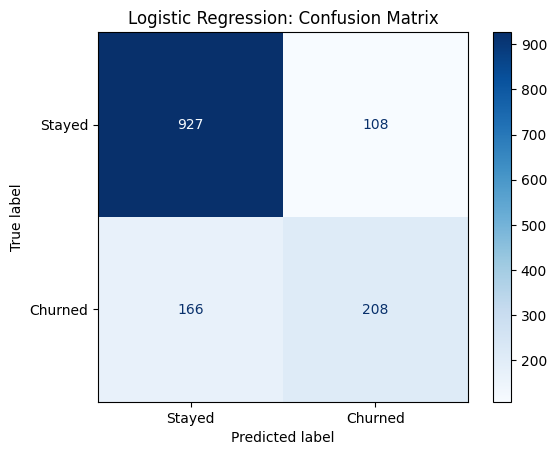

In [ ]:
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Logistic Regression: Confusion Matrix")
plt.show()

**The main metrics.** Each one answers a different question:

| Metric | Question | Formula |
|---|---|---|
| Accuracy | How many did we get right overall? | (TP+TN) / all |
| Precision | When we say "churn," how often are we right? ("don't cry wolf") | TP / (TP+FP) |
| Recall | Of all real churners, how many did we catch? ("don't miss any wolves") | TP / (TP+FN) |
| F1 | Balance of precision and recall | 2 x P x R / (P + R) |
| ROC-AUC | How well does the model rank churners above non-churners? (0.5 = random, 1.0 = perfect) | uses probabilities |

Note: ROC-AUC uses `y_prob` (probabilities), not `y_pred`, because it measures **ranking**, not one cut-off.

In [ ]:
print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("F1-score :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob), 3))

Accuracy : 0.806
Precision: 0.658
Recall   : 0.556
F1-score : 0.603
ROC-AUC  : 0.842


This is much better than the lazy model (it actually catches churners, and ROC-AUC is well above 0.5).
But **recall is only about 55%**: **almost half of the real churners are missed**. For the business, that's a lot of lost customers.

**Classification report:** precision, recall and F1 for **each class** in one table.
`support` = how many real customers are in each class.
Focus on the **"Churned"** row, because that's the class the business cares about.

In [ ]:
print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))

              precision    recall  f1-score   support

      Stayed       0.85      0.90      0.87      1035
     Churned       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



# Part D: Improving recall

**Balanced class weights.**
Churners are about 3 times rarer than non-churners, so during training the model sees far more "stayed" examples and leans towards predicting "stayed".
`class_weight="balanced"` makes **each mistake on a churner count about 3 times more** in the log loss, so the model pays more attention to catching them.
We train a second model (`log_bal`) and compute the same metrics and confusion matrix.

Accuracy : 0.74
Precision: 0.507
Recall   : 0.786
F1-score : 0.616
ROC-AUC  : 0.842


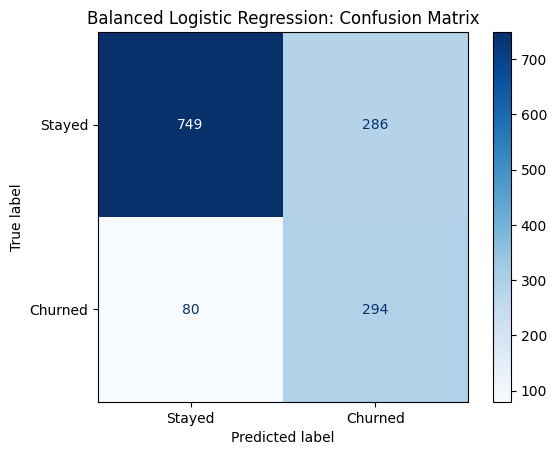

In [ ]:
log_bal = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")
log_bal.fit(X_train_scaled, y_train)

y_pred_bal = log_bal.predict(X_test_scaled)
y_prob_bal = log_bal.predict_proba(X_test_scaled)[:, 1]

print("Accuracy :", round(accuracy_score(y_test, y_pred_bal), 3))
print("Precision:", round(precision_score(y_test, y_pred_bal), 3))
print("Recall   :", round(recall_score(y_test, y_pred_bal), 3))
print("F1-score :", round(f1_score(y_test, y_pred_bal), 3))
print("ROC-AUC  :", round(roc_auc_score(y_test, y_prob_bal), 3))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred_bal),
                       display_labels=["Stayed", "Churned"]).plot(cmap="Blues")
plt.title("Balanced Logistic Regression: Confusion Matrix")
plt.show()

**The precision-recall trade-off.**
- **Recall went up a lot** (from about 0.55 to about 0.79): we now catch most churners.
- **Precision went down** (from about 0.65 to about 0.51): more false alarms (some loyal customers get an offer they didn't need).
- **Accuracy went down**, which is fine, because accuracy is not our goal here.
- **ROC-AUC stayed about the same**: the model's *ranking* ability didn't change. We only moved *where the line is drawn* between "churn" and "stay".

For churn this is a **good trade**: an unneeded discount is cheaper than a lost customer.

**Changing the decision threshold.**
By default, `predict` says "churn" when the probability is 0.5 or higher. We can choose a different cut-off ourselves.
Here we take the **normal** model's probabilities (`y_prob`) and try thresholds 0.3, 0.4, 0.5 and 0.6.
`(y_prob >= threshold).astype(int)` turns True/False into 1/0.

In [ ]:
for threshold in [0.3, 0.4, 0.5, 0.6]:
    pred_t = (y_prob >= threshold).astype(int)
    print(f"Threshold {threshold}:  Precision = {precision_score(y_test, pred_t):.2f}   "
          f"Recall = {recall_score(y_test, pred_t):.2f}")

Threshold 0.3:  Precision = 0.52   Recall = 0.76
Threshold 0.4:  Precision = 0.57   Recall = 0.67
Threshold 0.5:  Precision = 0.66   Recall = 0.56
Threshold 0.6:  Precision = 0.72   Recall = 0.40


**Lower threshold: higher recall, lower precision** (we flag more customers, catch more churners, but also raise more false alarms).
**Higher threshold: higher precision, lower recall.**

The business can choose the threshold based on its **budget**, for example how many customers the retention team can afford to contact each month.

# Part E: Interpretation and results table

**What did the model learn? Look at the coefficients (weights).**
We take the weights of the **balanced** model, attach the feature names, sort them, and draw a horizontal bar chart.
- **Red / positive**: increases the chance of churn
- **Green / negative**: decreases the chance of churn
- **Bigger bar** = stronger effect; **near 0** = barely matters

The coefficients are comparable with each other **because we scaled** the numeric features. Otherwise a column with big numbers (like TotalCharges) would get a tiny weight just because of its units.

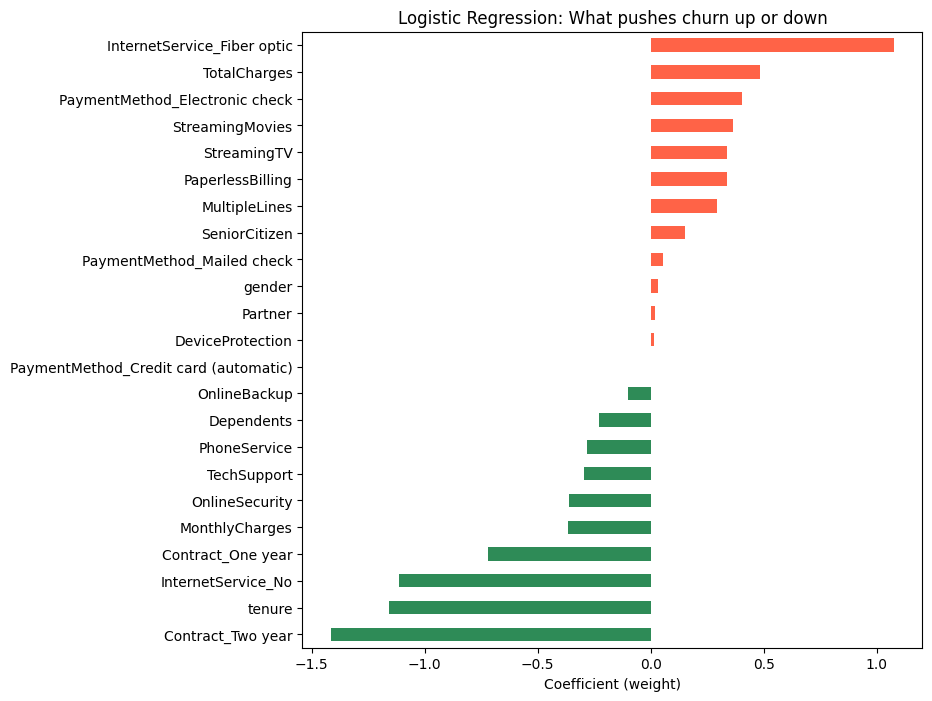

In [ ]:
coef = pd.Series(log_bal.coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 8))
coef.plot(kind="barh", color=["tomato" if c > 0 else "seagreen" for c in coef])
plt.title("Logistic Regression: What pushes churn up or down")
plt.xlabel("Coefficient (weight)")
plt.show()

**Top 3 features that increase churn and top 3 that decrease it** (as numbers, to read alongside the chart).

In [ ]:
print("Top 3 increasing churn (positive):")
print(coef.sort_values(ascending=False).head(3).round(3))
print()
print("Top 3 decreasing churn (negative):")
print(coef.head(3).round(3))

Top 3 increasing churn (positive):
InternetService_Fiber optic       1.078
TotalCharges                      0.486
PaymentMethod_Electronic check    0.406
dtype: float64

Top 3 decreasing churn (negative):
Contract_Two year    -1.416
tenure               -1.157
InternetService_No   -1.114
dtype: float64


**How to read this:**
- `tenure`, `Contract_Two year` and `Contract_One year` push churn **down**: loyal customers on long contracts stay.
- `InternetService_Fiber optic`, `PaymentMethod_Electronic check` and `PaperlessBilling` push churn **up**.
- These match the **EDA findings from Lesson 3**, which is a good sign the model learned real patterns.

**Multicollinearity:** `tenure` and `TotalCharges` are strongly correlated (0.83), because TotalCharges is roughly tenure times MonthlyCharges.
When two features carry almost the same information, the model can split the weight between them in strange ways, so their **individual** coefficients can look odd or counterintuitive (here **TotalCharges gets a positive weight** even though long-paying customers churn less, and **MonthlyCharges gets a negative weight** even though the EDA showed churners pay more. That's because MonthlyCharges also overlaps with Fiber optic and the streaming services, which already carry that "expensive plan" effect).

**Start the results table.**
We store the main metrics of each model in one DataFrame and save it to `data/model_results.csv`.
The "lazy" model has fixed values: 73.5% accuracy, 0 precision/recall/F1 (it never predicts churn), and ROC-AUC 0.5 (no better than random ranking).

Every future model (Decision Tree, Random Forest, XGBoost, neural network, and so on) will be **appended** to this table, so it tells the story from simple to advanced.

In [ ]:
model_results = pd.DataFrame([
    {"Model": "Lazy (predict all stay)", "Accuracy": 0.735, "Precision": 0, "Recall": 0, "F1": 0, "ROC-AUC": 0.5},
    {"Model": "Logistic Regression",
     "Accuracy": accuracy_score(y_test, y_pred), "Precision": precision_score(y_test, y_pred),
     "Recall": recall_score(y_test, y_pred), "F1": f1_score(y_test, y_pred),
     "ROC-AUC": roc_auc_score(y_test, y_prob)},
    {"Model": "Logistic Regression (balanced)",
     "Accuracy": accuracy_score(y_test, y_pred_bal), "Precision": precision_score(y_test, y_pred_bal),
     "Recall": recall_score(y_test, y_pred_bal), "F1": f1_score(y_test, y_pred_bal),
     "ROC-AUC": roc_auc_score(y_test, y_prob_bal)},
]).round(3)

model_results.to_csv("../data/model_results.csv", index=False)
model_results

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Lazy (predict all stay),0.735,0.000,0.000,0.000,0.500
1,Logistic Regression,0.806,0.658,0.556,0.603,0.842
2,Logistic Regression (balanced),0.740,0.507,0.786,0.616,0.842


## Findings (Lesson 5)
1. A "lazy" model predicting nobody churns gets 73.5% accuracy but catches 0 churners. **Accuracy is misleading on imbalanced data.**
2. Logistic Regression: about 80% accuracy, ROC-AUC about 0.84, but recall only about 55%.
3. With `class_weight="balanced"`, recall rises to about 79% and precision drops to about 51% (the **precision-recall trade-off**).
4. For churn, **recall matters more**, because a lost customer costs more than an unneeded discount.
5. Top drivers: long tenure and long contracts reduce churn; fiber optic and electronic check increase it. These match the EDA.
6. Limitation: **multicollinearity** between tenure and TotalCharges makes some coefficients hard to interpret.

## Why move to Lesson 6
Logistic Regression is **linear**: it adds each feature's effect separately and can't naturally learn combinations like
"short tenure **AND** fiber optic **AND** no tech support means very high risk."

Tree-based models (Decision Tree, then Random Forest, then XGBoost) learn such interactions automatically and are usually the strongest models for tabular data.